# 08 · Provenance ledger demo
Register a dummy dataset, record an experiment, flip one byte of a **copy**, watch the hash mismatch raise an INTEGRITY_ALERT, and see `verify()` catch edits to the chain itself. Uses a temporary ledger; the project ledger is untouched.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

In [2]:
import tempfile, shutil, sqlite3
from synera_core.provenance.ledger import Ledger
from synera_core.provenance.manifest import register_file
from synera_core.security.integrity import IntegrityGuard
tmp = Path(tempfile.mkdtemp()); led = Ledger(tmp / "demo.db", tmp / "demo.key")
data = tmp / "demo.csv"; pd.DataFrame({"x": np.arange(10), "y": np.arange(10) ** 2}).to_csv(data, index=False)
h, blk = register_file(led, data, "dataset", {"demo": True}, manifest_path=tmp / "data" / "MANIFEST.json")
exp = led.append("EXPERIMENT_RUN", {"note": "dummy run"}, artifact_hashes=[h])
print("registered", h[:16], "in block", blk.index, "| experiment block", exp.index, "| chain valid:", led.verify()["valid"])

registered d7e1279da0f5a150 in block 0 | experiment block 1 | chain valid: True


In [3]:
b = bytearray(data.read_bytes()); b[5] ^= 1; data.write_bytes(bytes(b))
res = IntegrityGuard(led).check_dataset(data)
print("HASH MISMATCH" if not res.ok else "ok", "| expected", res.expected_hash[:12], "actual", res.actual_hash[:12])
print("blocks now:", [x.block_type for x in led.iter_blocks()])

HASH MISMATCH | expected d7e1279da0f5 actual f42ebca63644
blocks now: ['DATASET_REGISTERED', 'EXPERIMENT_RUN', 'INTEGRITY_ALERT']


In [4]:
def tamper(kind):
    copy = tmp / f"c_{kind}.db"; shutil.copy(tmp / "demo.db", copy); con = sqlite3.connect(copy)
    for (n,) in con.execute("select name from sqlite_master where type='trigger'").fetchall(): con.execute(f"drop trigger {n}")
    if kind == "payload": con.execute("update blocks set payload_json = replace(payload_json, 'dummy', 'FORGED') where block_index = 1")
    if kind == "delete_middle": con.execute("delete from blocks where block_index = 1")
    con.commit(); con.close(); return Ledger(copy, tmp / "demo.key").verify()
for k in ["payload", "delete_middle"]: v = tamper(k); print(f"{k:14s} valid={v['valid']} issues={[i['code'] for i in v['issues']]}")

payload        valid=False issues=['PAYLOAD_TAMPERED']


delete_middle  valid=False issues=['PREV_HASH_MISMATCH']


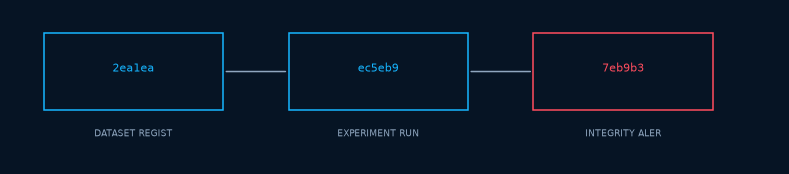

In [5]:
blocks = list(led.iter_blocks()); fig, ax = plt.subplots(figsize=(9, 1.8))
for i, b in enumerate(blocks):
    col = C["red"] if b.block_type == "INTEGRITY_ALERT" else C["cyan"]; ax.add_patch(plt.Rectangle((i * 1.5, 0), 1.1, 1, fill=False, ec=col)); ax.text(i * 1.5 + 0.55, 0.5, b.block_hash[:6], ha="center", color=col, fontsize=7)
    ax.text(i * 1.5 + 0.55, -0.35, b.block_type.replace("_", " ")[:14], ha="center", fontsize=6, color=C["muted"])
    if i: ax.annotate("", (i * 1.5, 0.5), (i * 1.5 - 0.4, 0.5), arrowprops=dict(arrowstyle="-", color=C["muted"]))
ax.set_xlim(-0.2, len(blocks) * 1.5); ax.set_ylim(-0.7, 1.3); ax.axis("off"); plt.show()